# Лабораторная работа № 1. Разведочный анализ

Дрынкин Иван САПР 1.3  

**Инструменты:** PySpark, HDFS, YARN, Apache Iceberg, Pandas, Matplotlib.

Цель — определить типы признаков, пропуски, дубликаты и выбросы, рассчитать описательную статистику, построить распределения и исследовать корреляции. Полная обработка выполняется в Spark; в Pandas переносятся только агрегаты и ограниченные выборки.

Датасет: https://www.kaggle.com/datasets/atalaydenknalbant/rawg-games-dataset?resource=download

## 1. Импорт библиотек и настройка Spark

In [1]:
import os
from pyspark import SparkConf
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.window import Window


def create_spark_configuration(app_name: str) -> SparkConf:
    """Настройка Spark для университетского кластера YARN и Apache Iceberg."""
    user_name = os.getenv("USER", "user0")

    conf = SparkConf()
    conf.setAppName(app_name)
    conf.setMaster("yarn")
    conf.set("spark.submit.deployMode", "client")
    conf.set("spark.executor.memory", "12g")
    conf.set("spark.executor.cores", "8")
    conf.set("spark.executor.instances", "2")
    conf.set("spark.driver.memory", "4g")
    conf.set("spark.driver.cores", "2")
    conf.set(
        "spark.jars.packages",
        "org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0"
    )
    conf.set(
        "spark.sql.extensions",
        "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions"
    )
    conf.set("spark.sql.catalog.spark_catalog", "org.apache.iceberg.spark.SparkCatalog")
    conf.set("spark.sql.catalog.spark_catalog.type", "hadoop")
    conf.set(
        "spark.sql.catalog.spark_catalog.warehouse",
        f"hdfs:///user/{user_name}/warehouse"
    )
    conf.set(
        "spark.sql.catalog.spark_catalog.io-impl",
        "org.apache.iceberg.hadoop.HadoopFileIO"
    )
    return conf

In [2]:
import math
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

### 1.1. Запуск Spark-сессии на YARN

In [3]:
conf = create_spark_configuration("drynkin RAWG exploratory analysis")
spark = SparkSession.builder.config(conf=conf).getOrCreate()
spark.sparkContext.setLogLevel("WARN")
spark

:: loading settings :: url = jar:file:/opt/spark-3.5.2-bin-hadoop3/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/user0/.ivy2/cache
The jars for the packages stored in: /home/user0/.ivy2/jars
org.apache.iceberg#iceberg-spark-runtime-3.5_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-f790543b-b52c-4850-b05e-9d0341c44449;1.0
	confs: [default]
	found org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 in central
:: resolution report :: resolve 648ms :: artifacts dl 27ms
	:: modules in use:
	org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   1   |   0   |   0   |   0   ||   1   |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spa

## 2. Чтение подготовленной таблицы Iceberg

Источник — таблица, созданная первым ноутбуком. Если она не найдена, проверьте успешность записи в Iceberg.

In [4]:
database_name = "drynkin_database"
table_name = "drynkin_lab1_table"
full_table_name = f"spark_catalog.{database_name}.{table_name}"

df = spark.table(full_table_name)
print(f"Источник анализа: {full_table_name}")
print("Типы данных:")
df.printSchema()

Источник анализа: spark_catalog.drynkin_database.drynkin_lab1_table
Типы данных:
root
 |-- id: long (nullable = true)
 |-- slug: string (nullable = true)
 |-- name: string (nullable = true)
 |-- released: date (nullable = true)
 |-- rating: double (nullable = true)
 |-- rating_top: double (nullable = true)
 |-- ratings_count: long (nullable = true)
 |-- reviews_text_count: long (nullable = true)
 |-- added: long (nullable = true)
 |-- metacritic: long (nullable = true)
 |-- playtime: double (nullable = true)
 |-- suggestions_count: long (nullable = true)
 |-- updated: timestamp (nullable = true)
 |-- reviews_count: long (nullable = true)
 |-- platforms: string (nullable = true)
 |-- stores: string (nullable = true)
 |-- developers: string (nullable = true)
 |-- genres: string (nullable = true)
 |-- tags: string (nullable = true)
 |-- publishers: string (nullable = true)
 |-- esrb_rating: string (nullable = true)
 |-- movies_count: long (nullable = true)
 |-- reddit_count: long (nullabl

### 2.1. Первичный просмотр записей

Проверяем, что нужные поля читаются и значения не смещены между столбцами.

In [5]:
df.select(
    "id", "name", "released", "rating", "ratings_count", "metacritic",
    "playtime", "genres", "parent_platforms", "developers"
).show(10, truncate=70)

+---+-------------------------------------+----------+------+-------------+----------+--------+---------------------------------------------+--------------------------------------------------------------+----------------------------------------------------------------------+
| id|                                 name|  released|rating|ratings_count|metacritic|playtime|                                       genres|                                              parent_platforms|                                                            developers|
+---+-------------------------------------+----------+------+-------------+----------+--------+---------------------------------------------+--------------------------------------------------------------+----------------------------------------------------------------------+
|  7|                            Laserlife|2015-09-22|  2.89|            8|      NULL|     5.0|                                 Action|Indie|                           PC|P

## 3. Размер набора и типы признаков

Фиксируем количество строк и столбцов, затем выводим схему Iceberg.

In [6]:
row_count = df.count()
column_count = len(df.columns)
print(f"Количество строк: {row_count:,}")
print(f"Количество столбцов: {column_count}")
print("Имена столбцов:")
print(df.columns)

Количество строк: 899,545
Количество столбцов: 33
Имена столбцов:
['id', 'slug', 'name', 'released', 'rating', 'rating_top', 'ratings_count', 'reviews_text_count', 'added', 'metacritic', 'playtime', 'suggestions_count', 'updated', 'reviews_count', 'platforms', 'stores', 'developers', 'genres', 'tags', 'publishers', 'esrb_rating', 'movies_count', 'reddit_count', 'achievements_count', 'youtube_count', 'twitch_count', 'parent_achievements_count', 'additions_count', 'screenshots_count', 'parent_platforms', 'game_series_count', 'parents_count', 'tba']


In [7]:
# Типы, зафиксированные в схеме Iceberg.
schema_report = pd.DataFrame(
    [(field.name, field.dataType.simpleString(), field.nullable) for field in df.schema.fields],
    columns=["column", "spark_type", "nullable"]
)
display(schema_report)

,column,spark_type,nullable
0,id,bigint,True
1,slug,string,True
2,name,string,True
3,released,date,True
4,rating,double,True
5,rating_top,double,True
6,ratings_count,bigint,True
7,reviews_text_count,bigint,True
8,added,bigint,True
9,metacritic,bigint,True


### 3.1. Семантические группы полей

`id` — технический ключ, а не измерительная величина. Даты, числовые метрики, категориальные поля и списки категорий анализируются разными методами.

In [8]:
identifier_columns = ["id", "slug", "name"]
date_columns = ["released", "updated"]
numeric_columns = [
    "rating", "rating_top", "ratings_count", "reviews_text_count", "added",
    "metacritic", "playtime", "suggestions_count", "reviews_count",
    "movies_count", "reddit_count", "achievements_count", "youtube_count",
    "twitch_count", "parent_achievements_count", "additions_count",
    "screenshots_count", "game_series_count", "parents_count"
]
multivalue_columns = [
    "platforms", "stores", "developers", "genres", "tags", "publishers", "parent_platforms"
]
categorical_columns = ["esrb_rating", "tba"]

print("Идентификаторы:", identifier_columns)
print("Даты:", date_columns)
print("Количественные признаки:", numeric_columns)
print("Многозначные категории:", multivalue_columns)
print("Категориальные признаки:", categorical_columns)

Идентификаторы: ['id', 'slug', 'name']
Даты: ['released', 'updated']
Количественные признаки: ['rating', 'rating_top', 'ratings_count', 'reviews_text_count', 'added', 'metacritic', 'playtime', 'suggestions_count', 'reviews_count', 'movies_count', 'reddit_count', 'achievements_count', 'youtube_count', 'twitch_count', 'parent_achievements_count', 'additions_count', 'screenshots_count', 'game_series_count', 'parents_count']
Многозначные категории: ['platforms', 'stores', 'developers', 'genres', 'tags', 'publishers', 'parent_platforms']
Категориальные признаки: ['esrb_rating', 'tba']


## 4. Пропущенные значения

Считаем NULL по всем полям. В категориях метка `Unknown` также считается отсутствующей информацией; числовые NULL не заменяются нулями.

In [9]:
missing_exprs = []
for column in df.columns:
    condition = F.col(column).isNull()
    if column in multivalue_columns + ["slug", "esrb_rating"]:
        condition = condition | (F.col(column) == "Unknown")
    missing_exprs.append(F.sum(F.when(condition, 1).otherwise(0)).alias(column))

missing_counts = df.agg(*missing_exprs).first().asDict()
missing_report = pd.DataFrame([
    {
        "column": column,
        "missing_count": int(missing_counts[column] or 0),
        "missing_percent": round(100 * int(missing_counts[column] or 0) / row_count, 3) if row_count else 0.0
    }
    for column in df.columns
]).sort_values(["missing_percent", "missing_count"], ascending=False)

display(missing_report)

26/10/29 23:54:40 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


,column,missing_count,missing_percent
32,tba,899545,100.000
27,additions_count,897739,99.799
22,reddit_count,897661,99.791
31,parents_count,896179,99.626
9,metacritic,892415,99.207
25,twitch_count,889691,98.905
7,reviews_text_count,889140,98.843
30,game_series_count,888729,98.798
24,youtube_count,888340,98.754
21,movies_count,886653,98.567


### 4.1. Визуализация полей с наибольшей долей пропусков

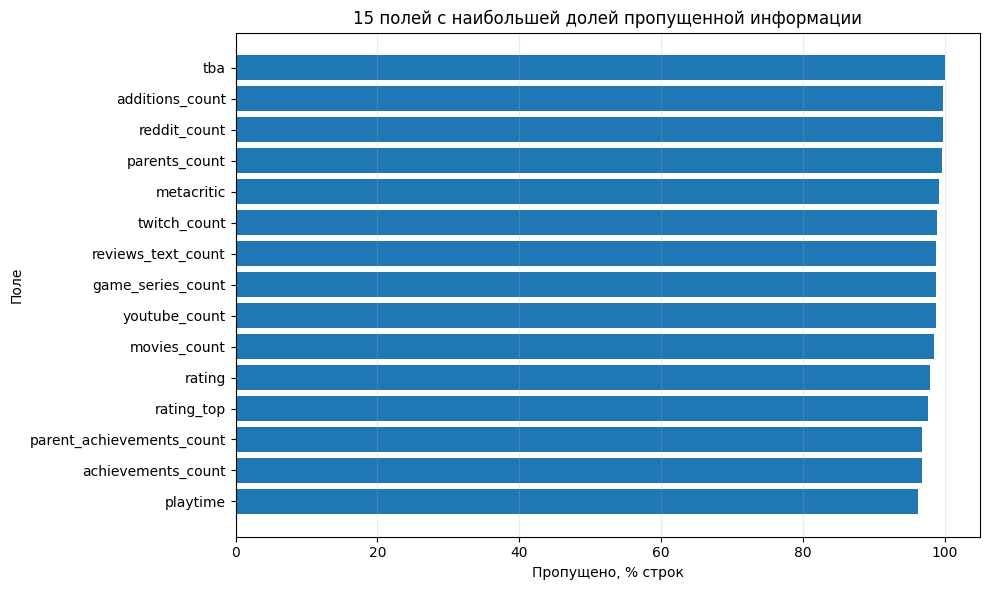

In [10]:
missing_top = missing_report.head(15).sort_values("missing_percent", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(missing_top["column"], missing_top["missing_percent"])
plt.xlabel("Пропущено, % строк")
plt.ylabel("Поле")
plt.title("15 полей с наибольшей долей пропущенной информации")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

### 4.2. Выводы по обработке пропусков

Пропуски рейтингов, Metacritic, дат и `playtime` влияют на число доступных наблюдений. Средние и корреляции рассчитываются по непустым значениям.

## 5. Проверка дубликатов

Повторно проверяем уникальность `id` и полные дубликаты. Совпадающее название не означает, что две записи представляют одну игру.

In [11]:
duplicate_id_groups = (
    df.groupBy("id").count()
      .filter(F.col("count") > 1)
      .orderBy(F.desc("count"))
)
print("Количество id с повторениями:", duplicate_id_groups.count())
duplicate_id_groups.show(10, truncate=False)

exact_duplicate_count = row_count - df.dropDuplicates().count()
print(f"Количество полных повторных строк: {exact_duplicate_count:,}")

Количество id с повторениями: 0


+---+-----+
|id |count|
+---+-----+
+---+-----+



Количество полных повторных строк: 0


## 6. Описательная статистика количественных признаков

Средние, стандартные отклонения, минимумы и максимумы считаются в Spark. Квартили оцениваются через `approxQuantile`, чтобы не переносить все значения на драйвер.

In [12]:
numeric_columns = [column for column in numeric_columns if column in df.columns]
summary_df = df.select(*numeric_columns).summary(
    "count", "mean", "stddev", "min", "max"
)
summary_df.show(truncate=False)

+-------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+-----------------+-----------------+-------------------------+------------------+-----------------+------------------+-------------------+
|summary|rating            |rating_top        |ratings_count     |reviews_text_count|added             |metacritic        |playtime          |suggestions_count |reviews_count     |movies_count      |reddit_count      |achievements_count|youtube_count    |twitch_count     |parent_achievements_count|additions_count   |screenshots_count|game_series_count |parents_count      |
+-------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+-----------

### 6.1. Квартили и медианы

In [13]:
quantile_values = df.approxQuantile(numeric_columns, [0.25, 0.50, 0.75], 0.01)
quantile_rows = []
for column, values in zip(numeric_columns, quantile_values):
    quantile_rows.append({
        "column": column,
        "Q1_25_percent": values[0] if len(values) > 0 else None,
        "median_50_percent": values[1] if len(values) > 1 else None,
        "Q3_75_percent": values[2] if len(values) > 2 else None,
    })
quantile_report = pd.DataFrame(quantile_rows)
display(quantile_report)

,column,Q1_25_percent,median_50_percent,Q3_75_percent
0,rating,2.9,3.5,3.92
1,rating_top,3.0,4.0,4.00
2,ratings_count,1.0,2.0,6.00
3,reviews_text_count,1.0,1.0,2.00
4,added,1.0,4.0,21.00
5,metacritic,66.0,74.0,80.00
6,playtime,1.0,2.0,4.00
7,suggestions_count,16.0,45.0,116.00
8,reviews_count,1.0,2.0,6.00
9,movies_count,1.0,1.0,1.00


### 6.2. Отдельная интерпретация рейтингов

`rating` имеет шкалу RAWG 0–5, `metacritic` — шкалу 0–100. Источники и методики различаются, поэтому абсолютные значения напрямую не сопоставляются.

In [14]:
rating_summary = df.agg(
    F.count("rating").alias("rating_non_null_count"),
    F.avg("rating").alias("rating_mean"),
    F.stddev("rating").alias("rating_stddev"),
    F.min("rating").alias("rating_min"),
    F.max("rating").alias("rating_max"),
    F.count("metacritic").alias("metacritic_non_null_count"),
    F.avg("metacritic").alias("metacritic_mean"),
    F.stddev("metacritic").alias("metacritic_stddev"),
    F.min("metacritic").alias("metacritic_min"),
    F.max("metacritic").alias("metacritic_max")
)
rating_summary.show(truncate=False)

+---------------------+-----------------+------------------+----------+----------+-------------------------+-----------------+------------------+--------------+--------------+
|rating_non_null_count|rating_mean      |rating_stddev     |rating_min|rating_max|metacritic_non_null_count|metacritic_mean  |metacritic_stddev |metacritic_min|metacritic_max|
+---------------------+-----------------+------------------+----------+----------+-------------------------+-----------------+------------------+--------------+--------------+
|18675                |3.373548594377508|0.7356119713563929|1.0       |4.83      |7130                     |72.20631136044881|11.835487528725293|15            |99            |
+---------------------+-----------------+------------------+----------+----------+-------------------------+-----------------+------------------+--------------+--------------+



## 7. Проверка аномальных значений

Повторно проверяем диапазоны рейтингов и отсутствие отрицательных счётчиков.

In [15]:
invalid_conditions = [
    ("rating outside [0, 5]", F.col("rating").isNotNull() & ~F.col("rating").between(0, 5)),
    ("rating_top outside [0, 5]", F.col("rating_top").isNotNull() & ~F.col("rating_top").between(0, 5)),
    ("metacritic outside [0, 100]", F.col("metacritic").isNotNull() & ~F.col("metacritic").between(0, 100)),
]
invalid_conditions.extend([
    (f"{column} < 0", F.col(column).isNotNull() & (F.col(column) < 0))
    for column in [c for c in numeric_columns if c not in ["rating", "rating_top", "metacritic"]]
])
invalid_counts = df.agg(*[
    F.sum(F.when(condition, 1).otherwise(0)).alias(label)
    for label, condition in invalid_conditions
]).first().asDict()
spark.createDataFrame(
    [(label, int(invalid_counts[label] or 0)) for label, _ in invalid_conditions],
    ["validation_rule", "invalid_rows"]
).show(40, truncate=False)

+-----------------------------+------------+
|validation_rule              |invalid_rows|
+-----------------------------+------------+
|rating outside [0, 5]        |0           |
|rating_top outside [0, 5]    |0           |
|metacritic outside [0, 100]  |0           |
|ratings_count < 0            |0           |
|reviews_text_count < 0       |0           |
|added < 0                    |0           |
|playtime < 0                 |0           |
|suggestions_count < 0        |0           |
|reviews_count < 0            |0           |
|movies_count < 0             |0           |
|reddit_count < 0             |0           |
|achievements_count < 0       |0           |
|youtube_count < 0            |0           |
|twitch_count < 0             |0           |
|parent_achievements_count < 0|0           |
|additions_count < 0          |0           |
|screenshots_count < 0        |0           |
|game_series_count < 0        |0           |
|parents_count < 0            |0           |
+---------

### 7.1. Выбросы по правилу межквартильного размаха (IQR)

Границы: `Q1 − 1.5 × IQR` и `Q3 + 1.5 × IQR`, где `IQR = Q3 − Q1`. Выбросы счётчиков фиксируем, но не удаляем автоматически: высокая популярность может быть реальной. В аналитической копии фильтруем только экстремальный `playtime`; Iceberg-таблица не меняется.

In [16]:
outlier_columns = [
    column for column in ["playtime", "ratings_count", "added", "reviews_count", "suggestions_count"]
    if column in df.columns
]
outlier_quantiles = df.approxQuantile(outlier_columns, [0.25, 0.75], 0.01)
outlier_specs = {}
outlier_rows = []

for column, quantiles in zip(outlier_columns, outlier_quantiles):
    if len(quantiles) != 2:
        continue
    q1, q3 = quantiles
    iqr = q3 - q1
    lower = max(0.0, q1 - 1.5 * iqr)
    upper = q3 + 1.5 * iqr
    outlier_specs[column] = (lower, upper, q1, q3, iqr)
    outlier_condition = F.col(column).isNotNull() & (
        (F.col(column) < lower) | (F.col(column) > upper)
    )
    outlier_rows.append({
        "column": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": int(df.filter(outlier_condition).count()),
    })

outlier_report = pd.DataFrame(outlier_rows)
display(outlier_report)

,column,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count
0,playtime,1.0,4.0,3.0,0.0,8.5,2515
1,ratings_count,1.0,6.0,5.0,0.0,13.5,11260
2,added,1.0,21.0,20.0,0.0,51.0,21620
3,reviews_count,1.0,6.0,5.0,0.0,13.5,11386
4,suggestions_count,16.0,116.0,100.0,0.0,266.0,70392


### 7.2. Проверка игр с экстремальным значением `playtime`

In [17]:
if "playtime" in outlier_specs and outlier_specs["playtime"][4] > 0:
    playtime_lower, playtime_upper, _, _, _ = outlier_specs["playtime"]
    playtime_outliers = df.filter(
        F.col("playtime").isNotNull()
        & ((F.col("playtime") < playtime_lower) | (F.col("playtime") > playtime_upper))
    )
    print(f"Границы IQR для playtime: [{playtime_lower:.3f}; {playtime_upper:.3f}]")
    print(f"Число строк с выбросами playtime: {playtime_outliers.count():,}")
    playtime_outliers.select("name", "released", "rating", "playtime", "ratings_count") \
        .orderBy(F.desc("playtime")).show(15, truncate=70)
    df_analysis = df.filter(
        F.col("playtime").isNull()
        | F.col("playtime").between(playtime_lower, playtime_upper)
    )
else:
    print("IQR не позволяет устойчиво выделить выбросы playtime; строки не удаляются.")
    df_analysis = df

analysis_row_count = df_analysis.count()
print(f"Строк до IQR-фильтрации: {row_count:,}")
print(f"Строк после IQR-фильтрации: {analysis_row_count:,}")
print(f"Исключено строк из df_analysis: {row_count - analysis_row_count:,}")

Границы IQR для playtime: [0.000; 8.500]
Число строк с выбросами playtime: 2,515


+----------------------------------------------------------------------------+----------+------+--------+-------------+
|                                                                        name|  released|rating|playtime|ratings_count|
+----------------------------------------------------------------------------+----------+------+--------+-------------+
|                                                     LurkBait Twitch Fishing|2024-02-21|  NULL|  2630.0|         NULL|
|                                                                      Shaiya|2007-12-24|  3.75|  1473.0|            8|
|                                             Fish Idle 2: Underwater Mystery|2024-11-15|  NULL|  1260.0|         NULL|
|                                                                 Spreadstorm|2018-06-13|  NULL|  1046.0|            1|
|                                                        Pokémon Gold, Silver|1999-11-21|  4.37|   900.0|          445|
|                                       

## 8. Частотный анализ жанров

Список в `genres` разделяем по `|` и разворачиваем через `explode`. Для жанров рассчитываем количество игр, средний рейтинг и число оценённых игр.

In [18]:
genre_counts = (
    df.filter(F.col("genres").isNotNull() & (F.col("genres") != "Unknown"))
      .withColumn("genre", F.explode(F.split(F.col("genres"), r"\|")))
      .withColumn("genre", F.trim(F.col("genre")))
      .filter((F.col("genre") != "") & (F.col("genre") != "Unknown"))
      .groupBy("genre")
      .agg(
          F.countDistinct("id").alias("games_count"),
          F.avg("rating").alias("average_rating"),
          F.count("rating").alias("rated_games_count")
      )
      .orderBy(F.desc("games_count"))
)
genre_pdf = genre_counts.limit(30).toPandas()
display(genre_pdf)

,genre,games_count,average_rating,rated_games_count
0,Action,191802,3.286635,8793
1,Adventure,152124,3.351514,6425
2,Platformer,100947,3.675584,951
3,Puzzle,97446,3.513947,1130
4,Indie,86724,3.091258,6616
5,Simulation,77046,3.284617,2634
6,Casual,67840,3.094590,3087
7,Strategy,62501,3.252820,3216
8,RPG,62058,3.350898,3798
9,Shooter,59636,3.434628,1599


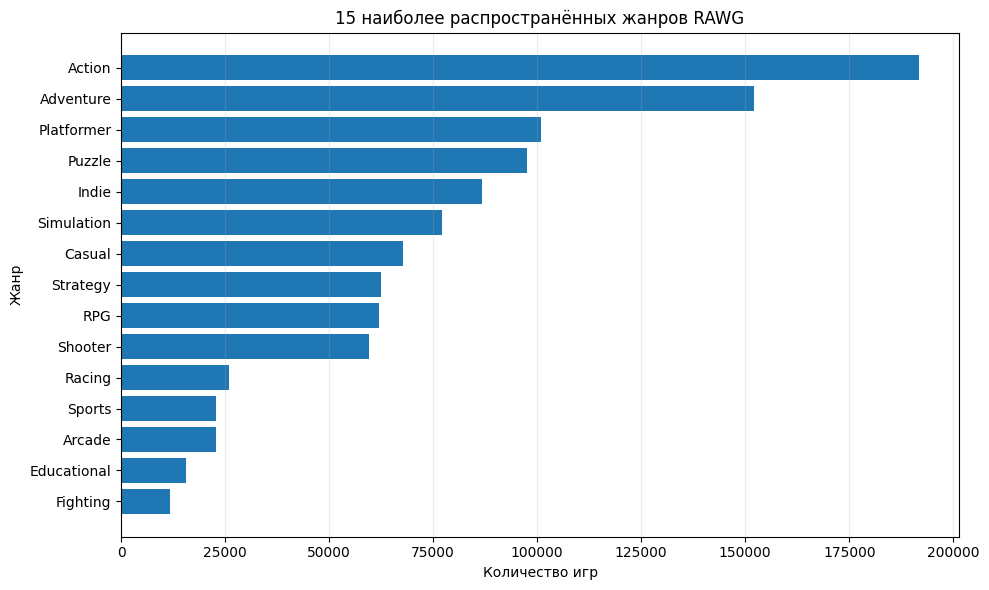

In [19]:
genre_plot = genre_pdf.head(15).sort_values("games_count", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(genre_plot["genre"], genre_plot["games_count"])
plt.xlabel("Количество игр")
plt.ylabel("Жанр")
plt.title("15 наиболее распространённых жанров RAWG")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

### 8.1. Рейтинг по жанрам

Рейтинг сравнивается только среди категорий с достаточным числом оценённых игр.

In [20]:
genre_rating = (
    genre_counts.filter(F.col("rated_games_count") >= 30)
                .orderBy(F.desc("average_rating"))
)
genre_rating.show(20, truncate=False)

+---------------------+-----------+------------------+-----------------+
|genre                |games_count|average_rating    |rated_games_count|
+---------------------+-----------+------------------+-----------------+
|Platformer           |100947     |3.6755835962145107|951              |
|Fighting             |11820      |3.6420348837209295|516              |
|Family               |5434       |3.552256809338521 |257              |
|Arcade               |22716      |3.5151955671447195|1534             |
|Puzzle               |97446      |3.5139469026548675|1130             |
|Card                 |4550       |3.4877862595419846|131              |
|Shooter              |59636      |3.4346278924327702|1599             |
|Educational          |15728      |3.404083333333333 |120              |
|Adventure            |152124     |3.351514396887159 |6425             |
|RPG                  |62058      |3.3508978409689316|3798             |
|Racing               |25843      |3.32420618556701

## 9. Анализ платформ

`parent_platforms` содержит семейства платформ, разделённые `|`. Рассчитываем количество игр и средние рейтинги по каждой категории.

In [21]:
platform_counts = (
    df.filter(F.col("parent_platforms").isNotNull() & (F.col("parent_platforms") != "Unknown"))
      .withColumn("platform", F.explode(F.split(F.col("parent_platforms"), r"\|")))
      .withColumn("platform", F.trim(F.col("platform")))
      .filter((F.col("platform") != "") & (F.col("platform") != "Unknown"))
      .groupBy("platform")
      .agg(
          F.countDistinct("id").alias("games_count"),
          F.avg("rating").alias("average_rating"),
          F.count("rating").alias("rated_games_count")
      )
      .orderBy(F.desc("games_count"))
)
platform_pdf = platform_counts.limit(30).toPandas()
display(platform_pdf)

,platform,games_count,average_rating,rated_games_count
0,PC,561247,3.291830,14921
1,Web,260048,3.747464,138
2,Apple Macintosh,108961,3.273099,4670
3,Linux,80453,3.238307,2782
4,iOS,77453,3.483900,2441
5,Android,52534,3.541107,1806
6,PlayStation,16005,3.504968,6842
7,Nintendo,15718,3.605197,5047
8,Xbox,9328,3.455367,4988
9,Commodore / Amiga,2084,3.619012,344


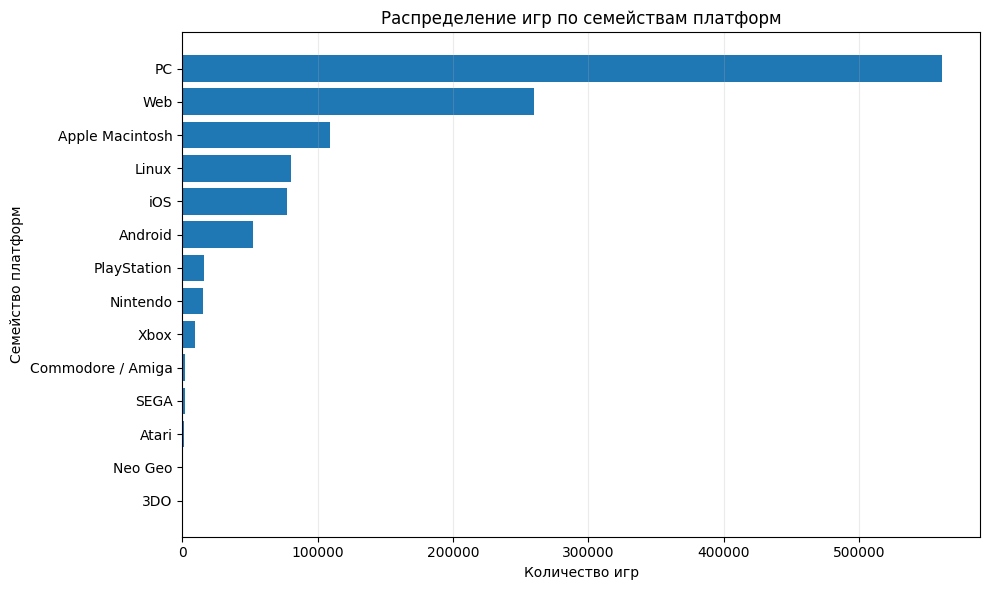

In [22]:
platform_plot = platform_pdf.head(15).sort_values("games_count", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(platform_plot["platform"], platform_plot["games_count"])
plt.xlabel("Количество игр")
plt.ylabel("Семейство платформ")
plt.title("Распределение игр по семействам платформ")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

### 9.1. Средний рейтинг по платформам

В рейтинговом сравнении оставляем платформы, у которых не менее 50 оценённых игр.

In [23]:
platform_rating = (
    platform_counts.filter(F.col("rated_games_count") >= 50)
                   .orderBy(F.desc("average_rating"))
)
platform_rating.show(25, truncate=False)

+-----------------+-----------+------------------+-----------------+
|platform         |games_count|average_rating    |rated_games_count|
+-----------------+-----------+------------------+-----------------+
|SEGA             |1882       |3.820690208667737 |623              |
|Web              |260048     |3.7474637681159417|138              |
|Commodore / Amiga|2084       |3.6190116279069775|344              |
|Nintendo         |15718      |3.6051971468198922|5047             |
|Atari            |1337       |3.5598467432950187|261              |
|Android          |52534      |3.541107419712071 |1806             |
|PlayStation      |16005      |3.5049678456591637|6842             |
|iOS              |77453      |3.4839000409668173|2441             |
|Xbox             |9328       |3.4553668805132323|4988             |
|PC               |561247     |3.2918296360833725|14921            |
|Apple Macintosh  |108961     |3.2730985010706632|4670             |
|Linux            |80453      |3.2

## 10. Магазины, разработчики и издатели

Многозначные поля разворачиваются по разделителю `|`; значения ранжируются по числу уникальных игр.

In [24]:
def explode_frequency(dataframe, source_column, result_column, limit=20):
    """Частота категорий в столбце, где несколько значений разделены вертикальной чертой."""
    return (
        dataframe.filter(F.col(source_column).isNotNull() & (F.col(source_column) != "Unknown"))
        .withColumn(result_column, F.explode(F.split(F.col(source_column), r"\|")))
        .withColumn(result_column, F.trim(F.col(result_column)))
        .filter((F.col(result_column) != "") & (F.col(result_column) != "Unknown"))
        .groupBy(result_column)
        .agg(F.countDistinct("id").alias("games_count"))
        .orderBy(F.desc("games_count"))
        .limit(limit)
    )

,store,games_count
0,itch.io,654163
1,Steam,123795
2,App Store,75594
3,Google Play,17128
4,Nintendo Store,9153
5,PlayStation Store,8085
6,GOG,7456
7,Xbox Store,4942
8,Xbox 360 Store,1915
9,Epic Games,1454


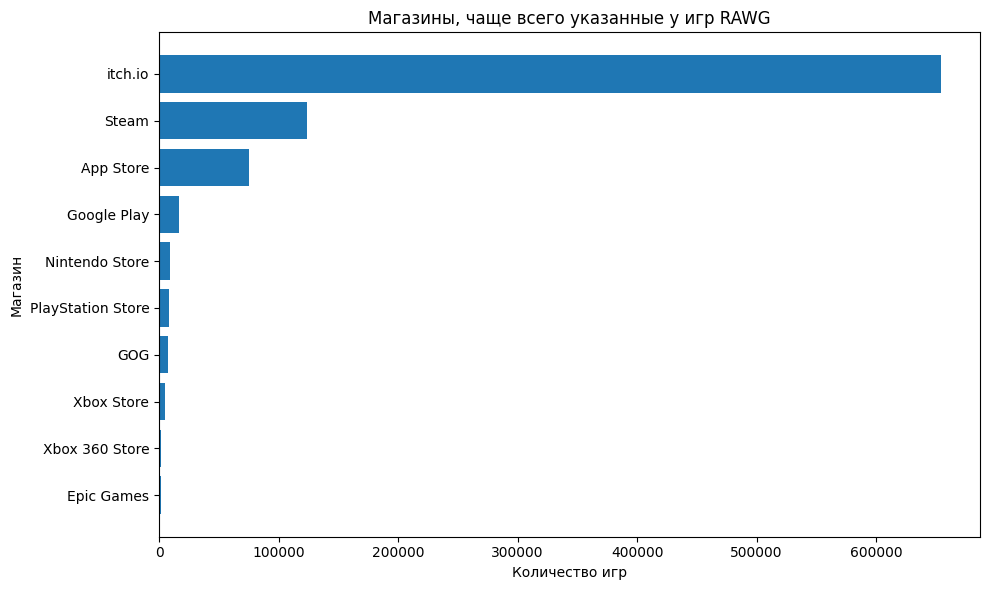

In [25]:
store_counts = explode_frequency(df, "stores", "store", limit=20)
store_pdf = store_counts.toPandas()
display(store_pdf)

store_plot = store_pdf.sort_values("games_count", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(store_plot["store"], store_plot["games_count"])
plt.xlabel("Количество игр")
plt.ylabel("Магазин")
plt.title("Магазины, чаще всего указанные у игр RAWG")
plt.tight_layout()
plt.show()

In [26]:
developer_counts = explode_frequency(df, "developers", "developer", limit=25)
developer_pdf = developer_counts.toPandas()
display(developer_pdf)

publisher_counts = explode_frequency(df, "publishers", "publisher", limit=25)
publisher_pdf = publisher_counts.toPandas()
display(publisher_pdf)

,developer,games_count
0,SEGA,585
1,Sony Interactive Entertainment,527
2,Konami Digital Entertainment,485
3,Capcom,480
4,Nintendo,429
5,Big Fish Games,394
6,Bardon,388
7,Game-U,388
8,Square Enix,377
9,Ubisoft,349


,publisher,games_count
0,Electronic Arts,1345
1,SEGA,1293
2,Nintendo,1244
3,Ubisoft Entertainment,1105
4,Big Fish Games,1014
5,Konami,877
6,Activision Blizzard,693
7,Capcom,648
8,Bandai Namco Entertainment,622
9,Square Enix,614


## 11. Распределения числовых признаков

Для графиков используется воспроизводимая выборка максимум 25 000 строк. Для сильно асимметричных счётчиков дополнительно строится `log1p`-шкала.

In [27]:
plot_columns = [
    column for column in ["rating", "metacritic", "playtime", "ratings_count", "added", "reviews_count"]
    if column in df_analysis.columns
]
plot_pdf = (
    df_analysis.select(*plot_columns)
    .sample(withReplacement=False, fraction=0.08, seed=42)
    .limit(25000)
    .toPandas()
)
print(f"Размер выборки для визуализации: {len(plot_pdf):,}")

for column in ["ratings_count", "added", "reviews_count"]:
    if column in plot_pdf.columns:
        plot_pdf[f"log1p_{column}"] = plot_pdf[column].apply(
            lambda value: math.log1p(value) if pd.notna(value) and value >= 0 else None
        )

Размер выборки для визуализации: 25,000


### 11.1. Гистограммы рейтинга, Metacritic и игрового времени

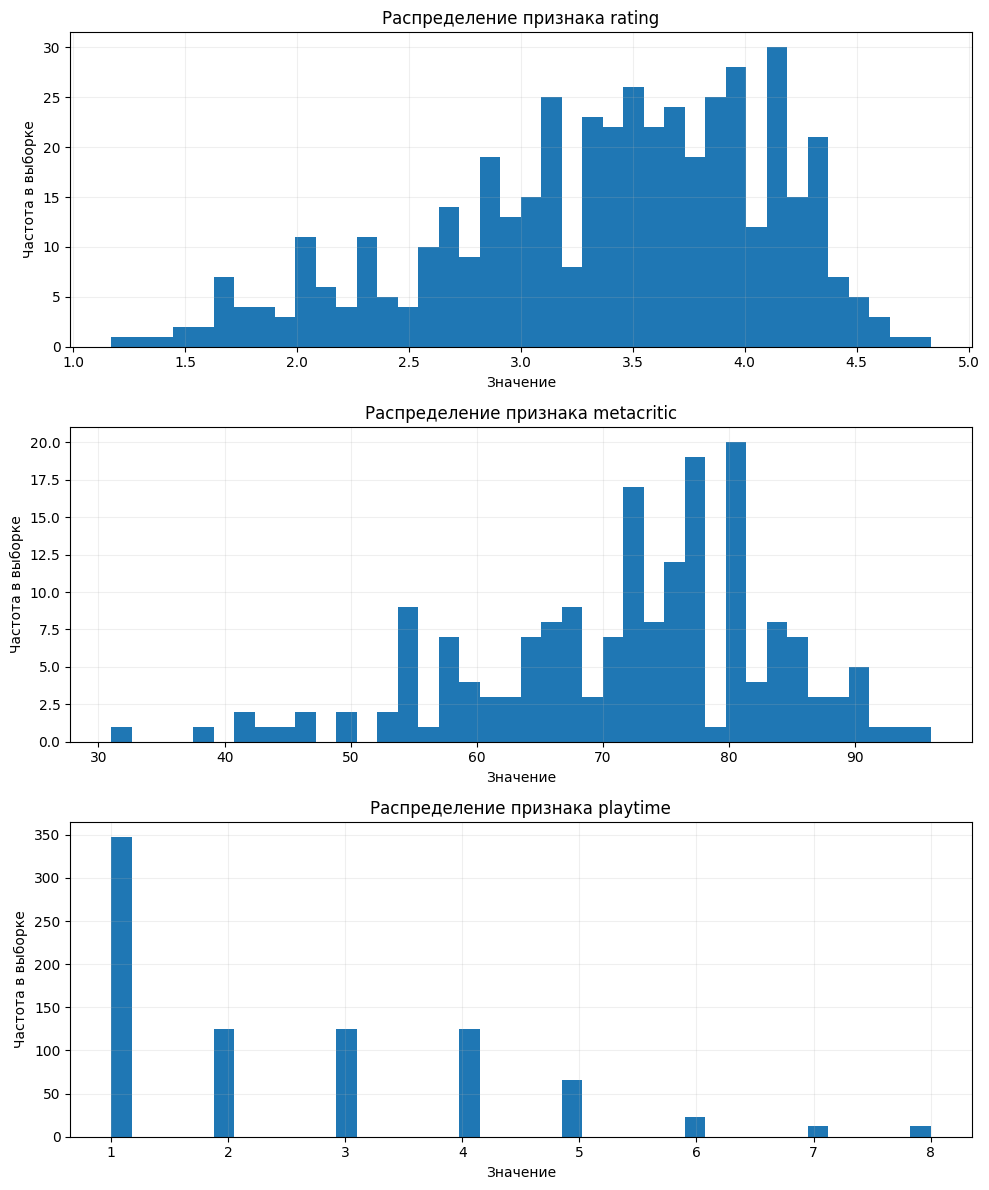

In [28]:
hist_columns = [
    column for column in ["rating", "metacritic", "playtime"]
    if column in plot_pdf.columns
]
fig, axes = plt.subplots(len(hist_columns), 1, figsize=(10, 4 * len(hist_columns)))
if len(hist_columns) == 1:
    axes = [axes]
for ax, column in zip(axes, hist_columns):
    values = pd.to_numeric(plot_pdf[column], errors="coerce").dropna()
    if not values.empty:
        ax.hist(values, bins=40)
    ax.set_title(f"Распределение признака {column}")
    ax.set_xlabel("Значение")
    ax.set_ylabel("Частота в выборке")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### 11.2. Распределения счётчиков после логарифмического преобразования

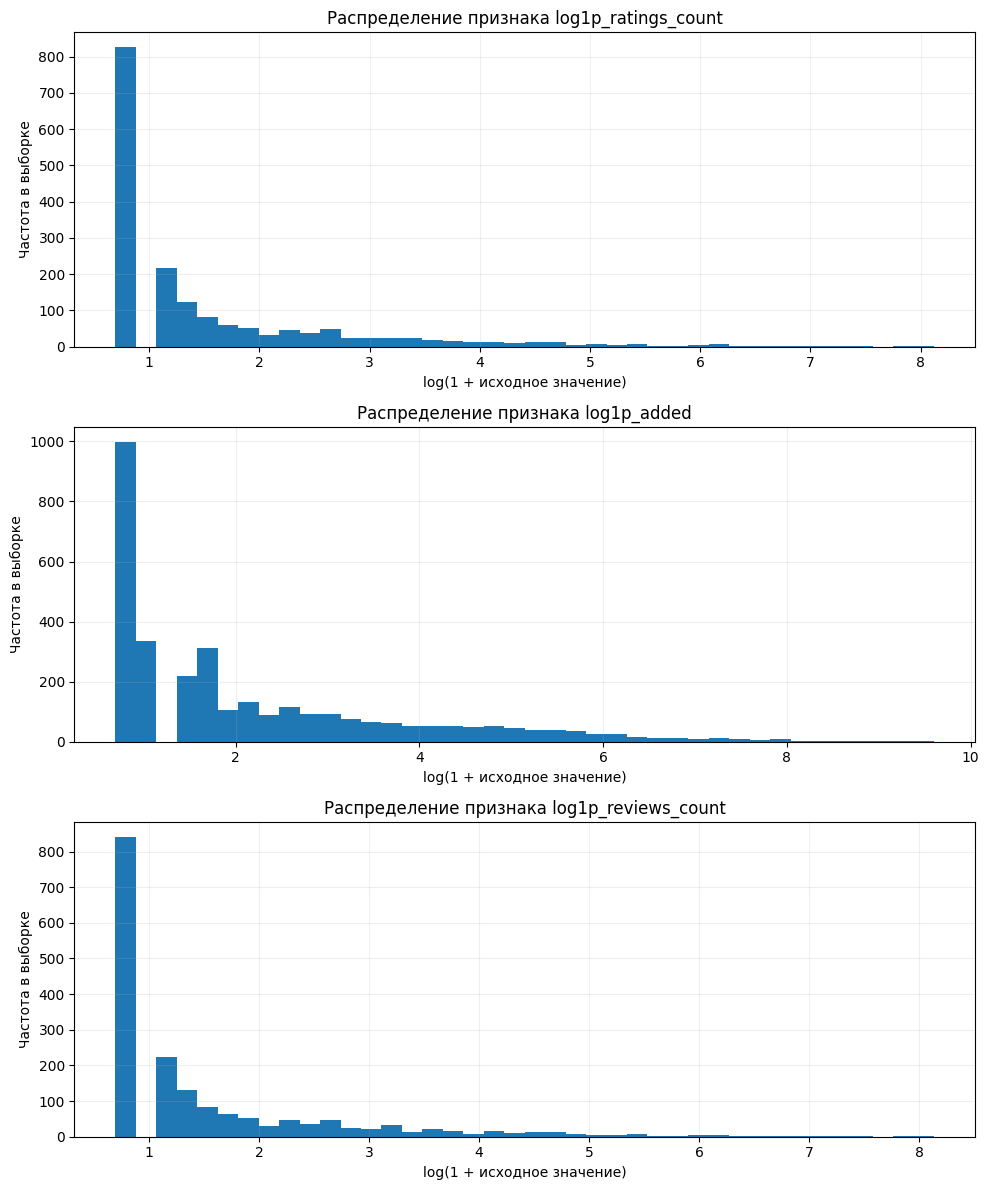

In [29]:
log_columns = [
    column for column in ["log1p_ratings_count", "log1p_added", "log1p_reviews_count"]
    if column in plot_pdf.columns
]
fig, axes = plt.subplots(len(log_columns), 1, figsize=(10, 4 * len(log_columns)))
if len(log_columns) == 1:
    axes = [axes]
for ax, column in zip(axes, log_columns):
    values = pd.to_numeric(plot_pdf[column], errors="coerce").dropna()
    if not values.empty:
        ax.hist(values, bins=40)
    ax.set_title(f"Распределение признака {column}")
    ax.set_xlabel("log(1 + исходное значение)")
    ax.set_ylabel("Частота в выборке")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 12. Распределение игр по годам выпуска

Для временной диаграммы используем даты начиная с 1970 года; записи без даты не учитываются.

In [30]:
release_year_counts = (
    df.filter(F.col("released").isNotNull())
      .withColumn("release_year", F.year("released"))
      .filter(F.col("release_year").between(1970, 2030))
      .groupBy("release_year")
      .agg(F.countDistinct("id").alias("games_count"))
)
print("Годы с наибольшим количеством игр:")
release_year_counts.orderBy(F.desc("games_count")).show(20, truncate=False)

year_pdf = release_year_counts.orderBy("release_year").toPandas()
display(year_pdf.tail(30))

Годы с наибольшим количеством игр:


+------------+-----------+
|release_year|games_count|
+------------+-----------+
|2022        |168156     |
|2021        |158685     |
|2020        |121340     |
|2019        |73676      |
|2018        |67951      |
|2023        |61950      |
|2017        |54576      |
|2016        |40247      |
|2015        |25898      |
|2025        |17953      |
|2024        |17511      |
|2014        |15361      |
|2013        |6346       |
|2012        |5390       |
|2011        |4334       |
|2010        |3913       |
|2009        |3159       |
|2008        |2097       |
|2007        |1685       |
|2006        |1417       |
+------------+-----------+
only showing top 20 rows



,release_year,games_count
31,2001,1221
32,2002,1128
33,2003,1308
34,2004,1336
35,2005,1317
36,2006,1417
37,2007,1685
38,2008,2097
39,2009,3159
40,2010,3913


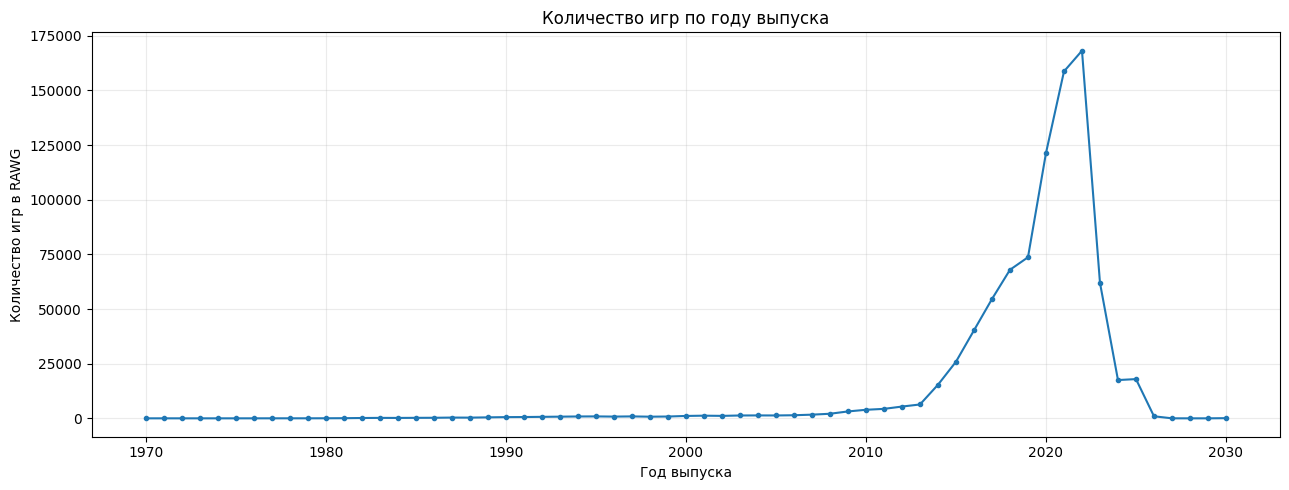

In [31]:
plt.figure(figsize=(13, 5))
plt.plot(year_pdf["release_year"], year_pdf["games_count"], marker="o", markersize=3)
plt.title("Количество игр по году выпуска")
plt.xlabel("Год выпуска")
plt.ylabel("Количество игр в RAWG")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### 12.1. Изменение среднего рейтинга во времени

Сравниваем средний рейтинг и число игр с доступными оценками по каждому году.

,release_year,average_rating,rated_games_count
27,1998,3.849189,185
28,1999,3.843557,253
29,2000,3.853975,244
30,2001,3.803640,261
31,2002,3.790427,234
32,2003,3.735316,301
33,2004,3.720528,322
34,2005,3.718692,344
35,2006,3.614563,355
36,2007,3.532807,374


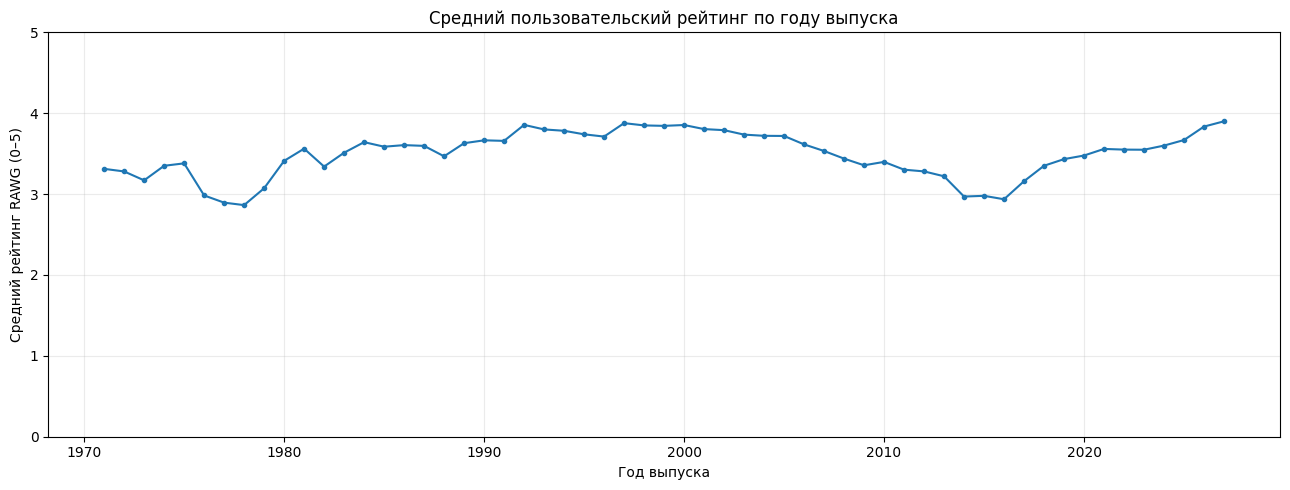

In [32]:
year_rating = (
    df.filter(F.col("released").isNotNull() & F.col("rating").isNotNull())
      .withColumn("release_year", F.year("released"))
      .filter(F.col("release_year").between(1970, 2030))
      .groupBy("release_year")
      .agg(
          F.avg("rating").alias("average_rating"),
          F.countDistinct("id").alias("rated_games_count")
      )
      .orderBy("release_year")
)
year_rating_pdf = year_rating.toPandas()
display(year_rating_pdf.tail(30))

plt.figure(figsize=(13, 5))
plt.plot(year_rating_pdf["release_year"], year_rating_pdf["average_rating"], marker="o", markersize=3)
plt.ylim(0, 5)
plt.title("Средний пользовательский рейтинг по году выпуска")
plt.xlabel("Год выпуска")
plt.ylabel("Средний рейтинг RAWG (0–5)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 13. Игры с высоким рейтингом и популярностью

Чтобы не ранжировать игры с единичными оценками наравне с популярными, для топа рейтингов используется порог в 100 оценок.

In [33]:
top_rated_games = (
    df.filter(F.col("rating").isNotNull() & (F.col("ratings_count") >= 100))
      .select("name", "released", "rating", "ratings_count", "metacritic", "genres")
      .orderBy(F.desc("rating"), F.desc("ratings_count"))
      .limit(30)
)
top_rated_games.show(30, truncate=75)

+---------------------------------------------+----------+------+-------------+----------+----------------------------+
|                                         name|  released|rating|ratings_count|metacritic|                      genres|
+---------------------------------------------+----------+------+-------------+----------+----------------------------+
|    The Witcher 3: Wild Hunt – Blood and Wine|2016-05-30|  4.81|          626|        92|                         RPG|
|   The Witcher 3 Wild Hunt - Complete Edition|2016-08-30|   4.8|          796|        92|               Adventure|RPG|
|   The Witcher 3: Wild Hunt – Hearts of Stone|2015-10-13|  4.76|          684|        90|                         RPG|
|                              Persona 5 Royal|2020-03-31|  4.75|          529|        94|               Adventure|RPG|
|                          Mass Effect Trilogy|2012-11-06|  4.74|          139|      NULL|          Action|Shooter|RPG|
|              Cyberpunk 2077: Phantom L

### 13.1. Самые обсуждаемые / популярные игры по счётчикам RAWG

In [34]:
most_rated_games = (
    df.filter(F.col("ratings_count").isNotNull())
      .select("name", "released", "rating", "ratings_count", "reviews_count", "added", "genres")
      .orderBy(F.desc("ratings_count"))
      .limit(30)
)
most_rated_games.show(30, truncate=75)

most_added_games = (
    df.filter(F.col("added").isNotNull())
      .select("name", "released", "rating", "ratings_count", "added", "genres")
      .orderBy(F.desc("added"))
      .limit(20)
)
most_added_games.show(20, truncate=75)

+---------------------------------------+----------+------+-------------+-------------+-----+----------------------------------------------------+
|                                   name|  released|rating|ratings_count|reviews_count|added|                                              genres|
+---------------------------------------+----------+------+-------------+-------------+-----+----------------------------------------------------+
|                     Grand Theft Auto V|2013-09-17|  4.47|         7409|         7544|22635|                                              Action|
|               The Witcher 3: Wild Hunt|2015-05-18|  4.64|         7234|         7354|22285|                                          Action|RPG|
|                               Portal 2|2011-04-18|  4.58|         6118|         6175|20926|                                      Shooter|Puzzle|
|                  Red Dead Redemption 2|2018-10-26|  4.59|         5525|         5658|16943|                         

## 14. Связь рейтинга RAWG и Metacritic

Scatter plot и корреляция строятся по выборке игр с обоими оценками. Корреляция не является доказательством причинной связи.

Наблюдений с обоими рейтингами в выборке: 597
Корреляция Pearson rating / metacritic: 0.5703


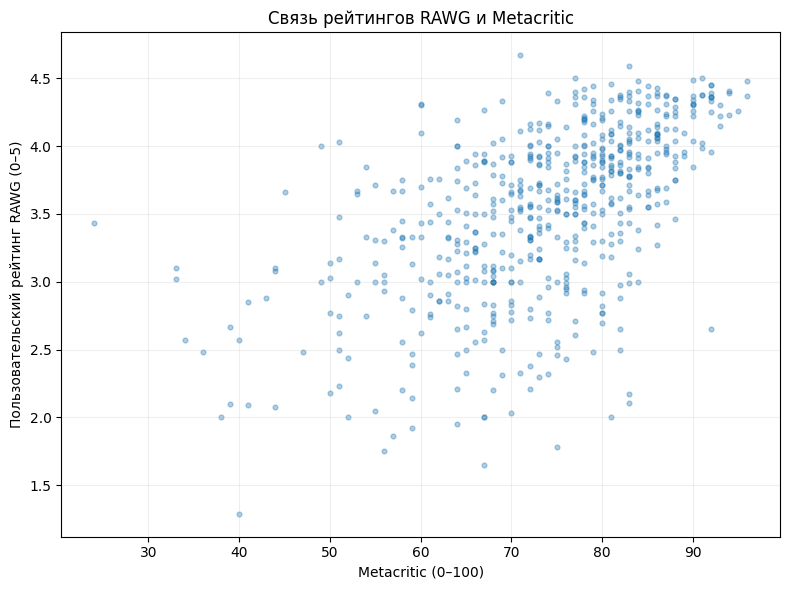

In [35]:
score_pdf = (
    df.filter(F.col("rating").isNotNull() & F.col("metacritic").isNotNull())
      .select("rating", "metacritic")
      .sample(withReplacement=False, fraction=0.1, seed=73)
      .limit(15000)
      .toPandas()
)
print(f"Наблюдений с обоими рейтингами в выборке: {len(score_pdf):,}")
if len(score_pdf) >= 2:
    print("Корреляция Pearson rating / metacritic:", round(score_pdf["rating"].corr(score_pdf["metacritic"]), 4))
    plt.figure(figsize=(8, 6))
    plt.scatter(score_pdf["metacritic"], score_pdf["rating"], alpha=0.35, s=12)
    plt.xlabel("Metacritic (0–100)")
    plt.ylabel("Пользовательский рейтинг RAWG (0–5)")
    plt.title("Связь рейтингов RAWG и Metacritic")
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

### 14.1. Нормализация Metacritic к шкале 0–5

Делим Metacritic на 20 для удобства сравнения средних. Шкалы не становятся полностью эквивалентными.

In [36]:
score_comparison = df.filter(
    F.col("rating").isNotNull() & F.col("metacritic").isNotNull()
).agg(
    F.count("id").alias("games_with_both_scores"),
    F.avg("rating").alias("rawg_mean_rating_0_5"),
    (F.avg("metacritic") / F.lit(20)).alias("metacritic_mean_scaled_0_5"),
    F.avg(F.abs(F.col("rating") - F.col("metacritic") / F.lit(20))).alias("mean_absolute_difference_after_scaling")
)
score_comparison.show(truncate=False)

+----------------------+--------------------+--------------------------+--------------------------------------+
|games_with_both_scores|rawg_mean_rating_0_5|metacritic_mean_scaled_0_5|mean_absolute_difference_after_scaling|
+----------------------+--------------------+--------------------------+--------------------------------------+
|5827                  |3.538688862193238   |3.685335507122018         |0.4155637549339278                    |
+----------------------+--------------------+--------------------------+--------------------------------------+



## 15. Корреляционный анализ

Строим корреляции Пирсона на ограниченной выборке. Для счётчиков добавляем `log1p`; ключ `id` исключён из-за отсутствия измерительного смысла.

In [37]:
corr_columns = [
    column for column in [
        "rating", "rating_top", "ratings_count", "reviews_text_count", "added",
        "metacritic", "playtime", "suggestions_count", "reviews_count",
        "achievements_count", "reddit_count"
    ] if column in df_analysis.columns
]

corr_pdf = (
    df_analysis.select(*corr_columns)
      .sample(withReplacement=False, fraction=0.08, seed=17)
      .limit(25000)
      .toPandas()
)
print(f"Размер выборки для корреляций: {len(corr_pdf):,}")
for column in ["ratings_count", "reviews_text_count", "added", "suggestions_count", "reviews_count", "achievements_count", "reddit_count"]:
    if column in corr_pdf.columns:
        corr_pdf[f"log1p_{column}"] = corr_pdf[column].apply(
            lambda value: math.log1p(value) if pd.notna(value) and value >= 0 else None
        )

corr_used_columns = [
    column for column in [
        "rating", "rating_top", "metacritic", "playtime",
        "log1p_ratings_count", "log1p_reviews_text_count", "log1p_added",
        "log1p_suggestions_count", "log1p_reviews_count",
        "log1p_achievements_count", "log1p_reddit_count"
    ] if column in corr_pdf.columns
]
corr_matrix = corr_pdf[corr_used_columns].corr(method="pearson", min_periods=30)
display(corr_matrix.round(3))

Размер выборки для корреляций: 25,000


,rating,rating_top,metacritic,playtime,log1p_ratings_count,log1p_reviews_text_count,log1p_added,log1p_suggestions_count,log1p_reviews_count,log1p_achievements_count,log1p_reddit_count
rating,1.000,0.849,0.623,0.169,0.204,0.171,-0.225,-0.042,0.209,0.027,-0.156
rating_top,0.849,1.000,0.457,0.156,0.175,0.089,-0.167,0.013,0.178,-0.107,-0.166
metacritic,0.623,0.457,1.000,0.178,0.509,0.246,0.404,-0.175,0.513,0.204,NaN
playtime,0.169,0.156,0.178,1.000,0.179,0.207,0.115,0.079,0.177,0.128,NaN
log1p_ratings_count,0.204,0.175,0.509,0.179,1.000,0.605,0.815,0.332,0.999,0.286,0.177
log1p_reviews_text_count,0.171,0.089,0.246,0.207,0.605,1.000,0.511,0.267,0.616,0.280,NaN
log1p_added,-0.225,-0.167,0.404,0.115,0.815,0.511,1.000,0.394,0.817,0.270,0.258
log1p_suggestions_count,-0.042,0.013,-0.175,0.079,0.332,0.267,0.394,1.000,0.334,0.097,0.136
log1p_reviews_count,0.209,0.178,0.513,0.177,0.999,0.616,0.817,0.334,1.000,0.292,0.182
log1p_achievements_count,0.027,-0.107,0.204,0.128,0.286,0.280,0.270,0.097,0.292,1.000,NaN


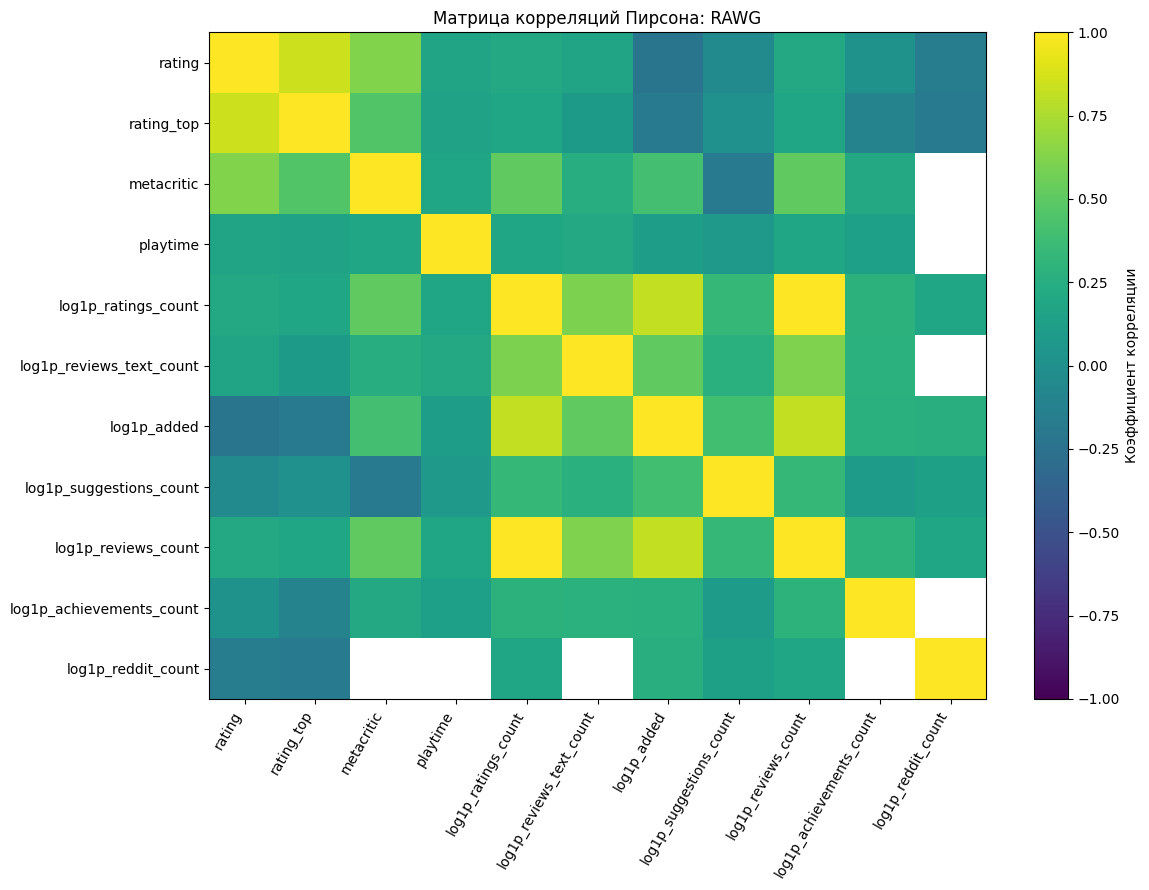

In [38]:
if not corr_matrix.empty:
    fig, ax = plt.subplots(figsize=(12, 9))
    image = ax.imshow(corr_matrix.values, vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(corr_matrix.columns)))
    ax.set_xticklabels(corr_matrix.columns, rotation=60, ha="right")
    ax.set_yticks(range(len(corr_matrix.index)))
    ax.set_yticklabels(corr_matrix.index)
    ax.set_title("Матрица корреляций Пирсона: RAWG")
    fig.colorbar(image, ax=ax, label="Коэффициент корреляции")
    plt.tight_layout()
    plt.show()

### 15.1. Наиболее выраженные парные корреляции

In [39]:
if not corr_matrix.empty:
    pair_rows = []
    for i, left in enumerate(corr_matrix.columns):
        for j in range(i + 1, len(corr_matrix.columns)):
            right = corr_matrix.columns[j]
            value = corr_matrix.loc[left, right]
            if pd.notna(value):
                pair_rows.append({"feature_1": left, "feature_2": right, "correlation": float(value)})
    strongest_pairs = pd.DataFrame(pair_rows)
    if not strongest_pairs.empty:
        strongest_pairs["absolute_correlation"] = strongest_pairs["correlation"].abs()
        strongest_pairs = strongest_pairs.sort_values("absolute_correlation", ascending=False)
        display(strongest_pairs.drop(columns="absolute_correlation").head(15).round(3))
    else:
        print("Недостаточно парных наблюдений для ранжирования корреляций.")

,feature_1,feature_2,correlation
35,log1p_ratings_count,log1p_reviews_count,0.999
0,rating,rating_top,0.849
43,log1p_added,log1p_reviews_count,0.817
33,log1p_ratings_count,log1p_added,0.815
1,rating,metacritic,0.623
40,log1p_reviews_text_count,log1p_reviews_count,0.616
32,log1p_ratings_count,log1p_reviews_text_count,0.605
24,metacritic,log1p_reviews_count,0.513
38,log1p_reviews_text_count,log1p_added,0.511
20,metacritic,log1p_ratings_count,0.509


## 16. Сопоставление популярности и рейтинга

На графике используется `log1p(ratings_count)`, чтобы длинный правый хвост был лучше виден.

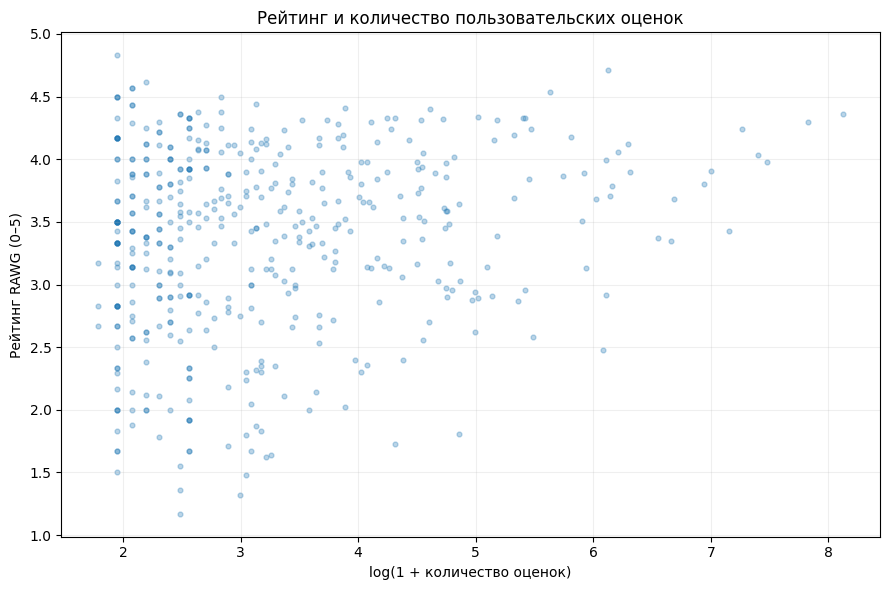

In [40]:
if "rating" in plot_pdf.columns and "ratings_count" in plot_pdf.columns:
    rating_popularity_pdf = plot_pdf[["rating", "ratings_count"]].dropna().copy()
    rating_popularity_pdf = rating_popularity_pdf[rating_popularity_pdf["ratings_count"] >= 0]
    if not rating_popularity_pdf.empty:
        rating_popularity_pdf["log1p_ratings_count"] = rating_popularity_pdf["ratings_count"].apply(math.log1p)
        plt.figure(figsize=(9, 6))
        plt.scatter(
            rating_popularity_pdf["log1p_ratings_count"],
            rating_popularity_pdf["rating"],
            alpha=0.3,
            s=12
        )
        plt.xlabel("log(1 + количество оценок)")
        plt.ylabel("Рейтинг RAWG (0–5)")
        plt.title("Рейтинг и количество пользовательских оценок")
        plt.grid(alpha=0.2)
        plt.tight_layout()
        plt.show()

## 17. Возрастной рейтинг ESRB

ESRB — категория возрастных ограничений, а не оценка качества. Сравниваем число игр и средний рейтинг по категориям.

In [41]:
esrb_summary = (
    df.groupBy("esrb_rating")
      .agg(
          F.countDistinct("id").alias("games_count"),
          F.avg("rating").alias("average_rating"),
          F.count("rating").alias("rated_games_count")
      )
      .orderBy(F.desc("games_count"))
)
esrb_summary.show(30, truncate=False)

+--------------+-----------+------------------+-----------------+
|esrb_rating   |games_count|average_rating    |rated_games_count|
+--------------+-----------+------------------+-----------------+
|Unknown       |828582     |3.2656909306786   |10949            |
|Everyone 10+  |43585      |3.4063344988344966|1716             |
|Teen          |14139      |3.5270206264323902|2618             |
|Mature        |6242       |3.6189552238805978|1742             |
|Everyone      |5505       |3.5504047619047623|1260             |
|Adults Only   |1392       |3.5618338108882526|349              |
|Rating Pending|100        |3.5402439024390246|41               |
+--------------+-----------+------------------+-----------------+



## 18. Сводка качества данных

Сводим размер таблицы, количество повторов и размер аналитической копии после IQR-фильтрации.

In [42]:
summary_values = [
    ("rows_in_iceberg", int(row_count)),
    ("columns_in_iceberg", int(column_count)),
    ("rows_in_analysis_copy_after_playtime_iqr", int(analysis_row_count)),
    ("rows_excluded_from_analysis_copy", int(row_count - analysis_row_count)),
    ("duplicate_id_groups", int(duplicate_id_groups.count())),
    ("exact_duplicate_rows", int(exact_duplicate_count)),
]
quality_summary = pd.DataFrame(summary_values, columns=["metric", "value"])
display(quality_summary)

,metric,value
0,rows_in_iceberg,899545
1,columns_in_iceberg,33
2,rows_in_analysis_copy_after_playtime_iqr,897030
3,rows_excluded_from_analysis_copy,2515
4,duplicate_id_groups,0
5,exact_duplicate_rows,0


## 19. Итоговые выводы

**1. Структура данных.** После очистки датасет содержит 899 545 записей и 33 столбца.

**2. Пропуски.** Больше всего пропусков в `tba` (100%), `metacritic` (99,207%), `rating` (97,924%) и `playtime` (96,246%).

**3. Дубликаты.** Повторяющиеся `id` и полные дубликаты строк не обнаружены.

**4. Статистика.** Средний рейтинг составляет 3,37, медиана — 3,50. Для `playtime` среднее равно 4,60, медиана — 2. Средний Metacritic — 72,21, медиана — 74.

**5. Выбросы.** По признаку `playtime` выявлено и исключено из аналитической копии 2 515 строк. Наибольшее количество выбросов среди пяти проверенных признаков обнаружено в `suggestions_count` — 70 392.

**6. Категории и время.** Самые распространённые жанры — Action (191 802 игры) и Adventure (152 124). Лидирующая платформа — PC (561 247 игр). Больше всего записей о выпуске приходится на 2022 год — 168 156.

**7. Корреляции.** Наиболее сильная связь обнаружена между количеством оценок и отзывов (0,999). Корреляция `rating` с `rating_top` составляет 0,849, а с `metacritic` — 0,623. Корреляция не доказывает причинно-следственную связь.

В результате выполнен разведочный анализ датасета RAWG, изучены качество данных, распределения признаков и взаимосвязи между показателями игр.

## 20. Завершение работы



In [43]:
# После выполнения всех разделов освободите ресурсы приложения YARN.
spark.stop()